# AcademiQ - Notebook 05: Student Clustering Analysis

This notebook explores unsupervised student segmentation using K-Means clustering across 43 preprocessed academic and lifestyle features.


In [1]:
import os
from pathlib import Path

def get_project_root():
    current = Path.cwd().resolve()
    for candidate in [current, current.parent, current.parent.parent]:
        if (candidate / "data" / "raw").exists() or (candidate / "requirements.txt").exists():
            return candidate
    return current

PROJECT_ROOT = get_project_root()
os.chdir(PROJECT_ROOT)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import zipfile

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    files = None

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option("display.max_columns", None)
print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
import os
from pathlib import Path
import pandas as pd

processed_dir = PROJECT_ROOT / "data" / "processed"
train_file = processed_dir / "AcademiQ_Train_Cleaned.csv"
test_file = processed_dir / "AcademiQ_Test_Cleaned.csv"

if not train_file.exists() and os.path.exists("/content/AcademiQ_Train_Cleaned.csv"):
    train_file = Path("/content/AcademiQ_Train_Cleaned.csv")
    test_file = Path("/content/AcademiQ_Test_Cleaned.csv")

train_df = pd.read_csv(train_file)
test_df = pd.read_csv(test_file)

print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)
display(train_df.head())


Training dataset: (5285, 20)
Testing dataset: (1322, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,27,79,Low,High,Yes,8,63,High,Yes,2,Low,Medium,Public,Negative,5,No,College,Moderate,Female,69
1,16,86,High,Medium,Yes,7,94,Medium,Yes,2,Low,High,Public,Neutral,3,No,High School,Moderate,Female,69
2,22,87,Low,Medium,No,8,83,Low,Yes,1,Low,Medium,Public,Neutral,1,No,College,Far,Male,66
3,18,100,High,Medium,Yes,10,86,Medium,Yes,1,Medium,Medium,Public,Neutral,3,No,High School,Near,Male,72
4,35,78,High,Low,Yes,10,99,Medium,Yes,1,Low,Medium,Private,Positive,2,No,High School,Near,Male,72


In [3]:
target = "Exam_Score"

X_train = train_df.drop(columns=[target])
X_test = test_df.drop(columns=[target])

y_train_score = train_df[target]
y_test_score = test_df[target]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (5285, 19)
Testing features: (1322, 19)


In [4]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']

Categorical features:
['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


C:\Users\mansi\AppData\Local\Temp\ipykernel_7516\1124402278.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [5]:
numeric_pipeline = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [6]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (5285, 43)
Processed testing shape: (1322, 43)


In [7]:
print("Training data contains missing values:",
      np.isnan(X_train_processed).sum())

print("Testing data contains missing values:",
      np.isnan(X_test_processed).sum())

Training data contains missing values: 0
Testing data contains missing values: 0


In [8]:
inertia_values = []

k_values = range(2, 9)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_train_processed)

    inertia_values.append(kmeans.inertia_)

print("Inertia calculation completed.")

Inertia calculation completed.


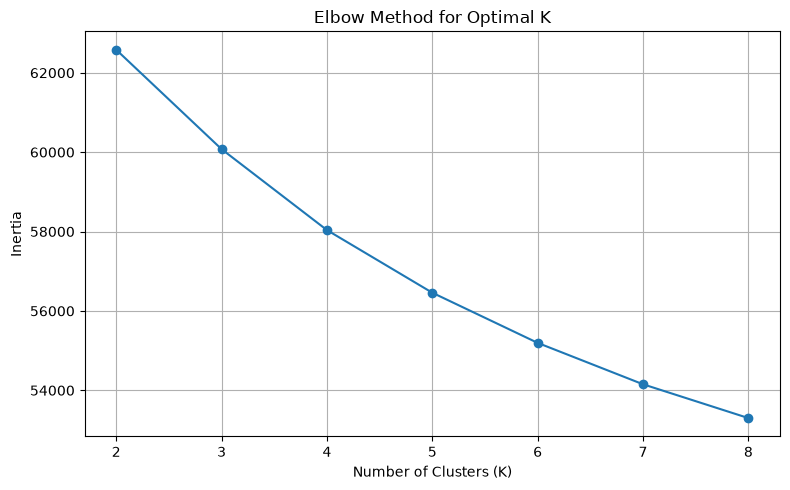

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()

In [10]:
silhouette_values = []

for k in range(2, 9):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(
        X_train_processed
    )

    score = silhouette_score(
        X_train_processed,
        cluster_labels,
        sample_size=min(1500, len(X_train_processed)),
        random_state=42
    )

    silhouette_values.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.0580
K = 3, Silhouette Score = 0.0522
K = 4, Silhouette Score = 0.0490
K = 5, Silhouette Score = 0.0486
K = 6, Silhouette Score = 0.0468
K = 7, Silhouette Score = 0.0455
K = 8, Silhouette Score = 0.0440


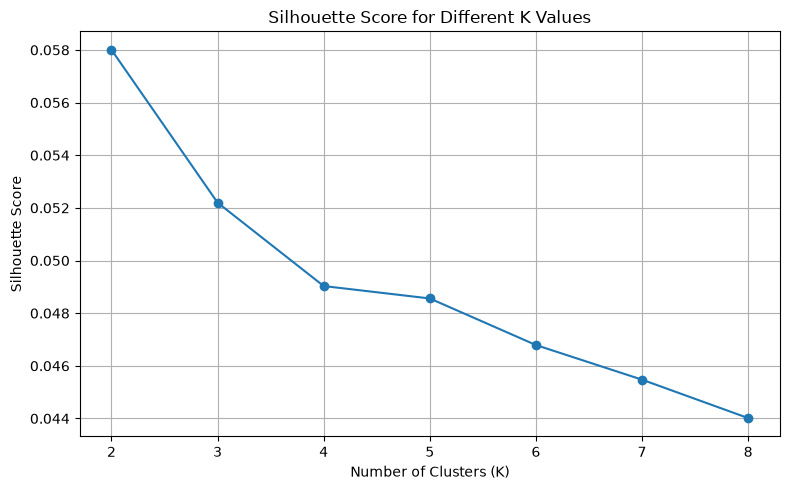

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(range(2, 9)),
    silhouette_values,
    marker="o"
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.grid(True)
plt.tight_layout()
plt.show()

### Cluster Separation and Silhouette Score Interpretation (Methodological Note)

The silhouette analysis identifies $K=2$ as having the highest relative score ($\\approx 0.058$). However, a silhouette coefficient close to 0 indicates substantial overlap between clusters without sharp geometric boundaries.

Furthermore, examining the actual examination score distributions demonstrates that Cluster 0 (mean $\\approx 67.73$, std $\\approx 3.98$) and Cluster 1 (mean $\\approx 66.72$, std $\\approx 3.80$) have virtually identical distributions.

**Conclusion:** The student dataset exhibits continuous multivariate variability rather than isolated, discrete student types. Therefore, K-Means is utilized as an **exploratory profiling technique** to observe general feature tendencies across groups, rather than claiming to have discovered definitive, rigid student archetypes.


In [12]:
best_k = list(range(2, 9))[
    np.argmax(silhouette_values)
]

print("K with highest silhouette score:", best_k)

K with highest silhouette score: 2


In [13]:
final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

train_clusters = final_kmeans.fit_predict(
    X_train_processed
)

test_clusters = final_kmeans.predict(
    X_test_processed
)

print("Final K-Means model trained.")
print("Number of clusters:", best_k)

Final K-Means model trained.
Number of clusters: 2


In [14]:
train_clustered = train_df.copy()
test_clustered = test_df.copy()

train_clustered["Cluster"] = train_clusters
test_clustered["Cluster"] = test_clusters

print("Training cluster distribution:")
display(
    train_clustered["Cluster"].value_counts().sort_index()
)

print("\nTesting cluster distribution:")
display(
    test_clustered["Cluster"].value_counts().sort_index()
)

Training cluster distribution:


Cluster
0    2590
1    2695
Name: count, dtype: int64


Testing cluster distribution:


Cluster
0    655
1    667
Name: count, dtype: int64

In [15]:
cluster_sizes = (
    train_clustered["Cluster"]
    .value_counts()
    .sort_index()
    .reset_index()
)

cluster_sizes.columns = [
    "Cluster",
    "Number_of_Students"
]

cluster_sizes["Percentage"] = (
    cluster_sizes["Number_of_Students"]
    / len(train_clustered)
) * 100

display(cluster_sizes.round(2))

,Cluster,Number_of_Students,Percentage
0,0,2590,49.01
1,1,2695,50.99


In [16]:
numeric_profile = (
    train_clustered
    .groupby("Cluster")[numerical_features]
    .mean()
)

display(numeric_profile.round(2))

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity
Cluster,,,,,,
0,20.24,79.05,6.95,87.68,1.43,2.92
1,19.71,80.66,7.10,62.94,1.57,3.02


In [17]:
categorical_profile = (
    train_clustered
    .groupby("Cluster")[categorical_features]
    .agg(
        lambda column: (
            column.mode().iloc[0]
            if not column.mode().empty
            else "Unknown"
        )
    )
)

display(categorical_profile)

,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Motivation_Level,Internet_Access,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
Cluster,,,,,,,,,,,,,
0,Medium,Medium,Yes,Medium,Yes,Medium,Medium,Public,Positive,No,High School,Near,Male
1,Medium,Medium,Yes,Medium,Yes,Low,Medium,Public,Positive,No,High School,Near,Male


In [18]:
score_profile = (
    train_clustered
    .groupby("Cluster")["Exam_Score"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

display(score_profile.round(2))

,count,mean,median,std,min,max
Cluster,,,,,,
0,2590,67.73,68.0,3.98,57,100
1,2695,66.72,67.0,3.80,56,100


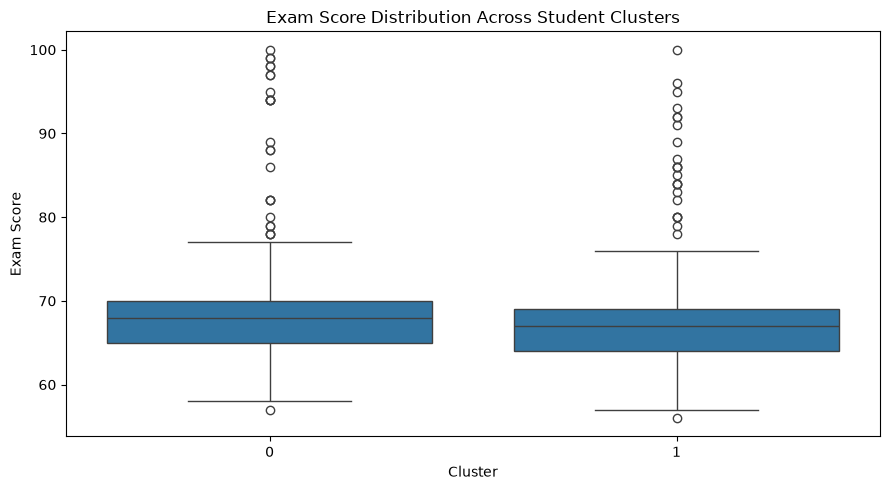

In [19]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=train_clustered,
    x="Cluster",
    y="Exam_Score"
)

plt.title("Exam Score Distribution Across Student Clusters")
plt.xlabel("Cluster")
plt.ylabel("Exam Score")
plt.tight_layout()
plt.show()

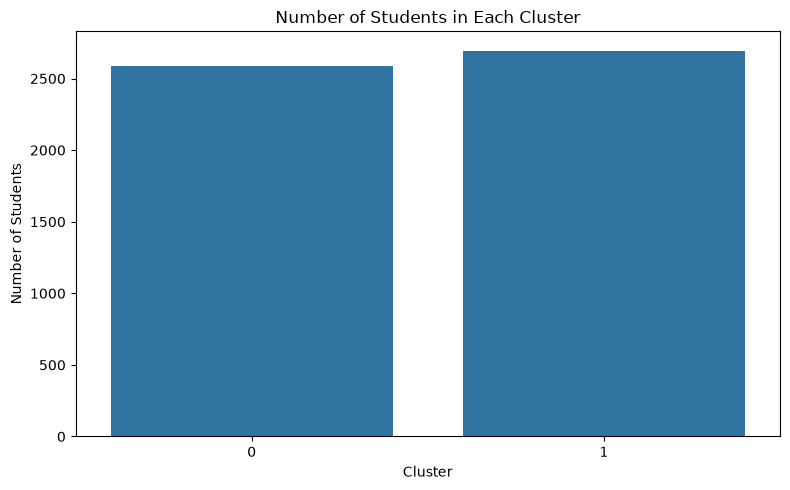

In [20]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_clustered,
    x="Cluster"
)

plt.title("Number of Students in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

In [21]:
final_silhouette = silhouette_score(
    X_train_processed,
    train_clusters,
    sample_size=min(1500, len(X_train_processed)),
    random_state=42
)

print("Final number of clusters:", best_k)
print("Final silhouette score:", round(final_silhouette, 4))

Final number of clusters: 2
Final silhouette score: 0.058


In [22]:
processed_dir = PROJECT_ROOT / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

train_clustered.to_csv(processed_dir / "AcademiQ_Train_Clustered.csv", index=False)
test_clustered.to_csv(processed_dir / "AcademiQ_Test_Clustered.csv", index=False)

print("Clustered datasets saved successfully to data/processed/.")


Clustered datasets saved successfully to data/processed/.


In [23]:
results_clust_dir = PROJECT_ROOT / "results" / "clustering"
results_clust_dir.mkdir(parents=True, exist_ok=True)

clustering_results = pd.DataFrame({
    "K": list(range(2, 9)),
    "Inertia": inertia_values,
    "Silhouette_Score": silhouette_values
})

clustering_results.to_csv(results_clust_dir / "AcademiQ_Clustering_Evaluation.csv", index=False)
display(clustering_results.round(4))


,K,Inertia,Silhouette_Score
0,2,62579.6825,0.0580
1,3,60075.3552,0.0522
2,4,58036.6950,0.0490
3,5,56458.8037,0.0486
4,6,55195.0566,0.0468
5,7,54152.3549,0.0455
6,8,53300.8000,0.0440


In [24]:
results_clust_dir = PROJECT_ROOT / "results" / "clustering"
results_clust_dir.mkdir(parents=True, exist_ok=True)

numeric_profile.to_csv(results_clust_dir / "AcademiQ_Numerical_Cluster_Profiles.csv")
categorical_profile.to_csv(results_clust_dir / "AcademiQ_Categorical_Cluster_Profiles.csv")
score_profile.to_csv(results_clust_dir / "AcademiQ_Cluster_Score_Analysis.csv")
cluster_sizes.to_csv(results_clust_dir / "AcademiQ_Cluster_Sizes.csv", index=False)

print("Cluster analysis files saved successfully to results/clustering/.")


Cluster analysis files saved successfully to results/clustering/.


In [25]:
models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(final_kmeans, models_dir / "AcademiQ_KMeans_Model.pkl")
joblib.dump(preprocessor, models_dir / "AcademiQ_Clustering_Preprocessor.pkl")

# Complete pipeline for maximum portability
clustering_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("clusterer", final_kmeans)
])
joblib.dump(clustering_pipeline, models_dir / "AcademiQ_Clustering_Pipeline.pkl")

print("K-Means model, preprocessor, and end-to-end pipeline saved successfully to models/.")


K-Means model, preprocessor, and end-to-end pipeline saved successfully to models/.


In [26]:
print("All clustering outputs successfully organized in data/processed/, results/clustering/, and models/.")


All clustering outputs successfully organized in data/processed/, results/clustering/, and models/.
